# Homework06

Some exercises with `pandas` `DataFrame`.

## Goals
- Get familiar with the `DataFrame` object and its functionalities
- Experiment with `DataFrame` filtering and searching

## Navigating Data

In this exercise we're going to explore the search and filter capabilities of the `DataFrame` to connect a couple of datasets and solve a mystery.

This is based on the [SQL Murder Mystery](https://mystery.knightlab.com/) exercise, but using different datasets created specifically for `pandas` and `DataFrame` objects.

Run the following $2$ cells to load the data and libraries we'll need.

In [2]:
!wget -q "https://github.com/PSAM-5020-2026F-A/Homework06/raw/main/Homework06_utils.pyc" -O Homework06_utils.pyc
!wget -qO- https://github.com/PSAM-5020-2026F-A/5020-utils/releases/latest/download/mystery.tar.gz | tar xz

In [3]:
import pandas as pd
from Homework06_utils import MysteryUtils

no gradio


### The Data

We'll be working with data from $6$ different sources:

- `report.csv`: Database of reported crimes
- `testimony.csv`: Database of testimony taken by police
- `license.csv`: DMV data
- `person.csv`: Names, addresses, social security numbers
- `update.csv`: List of social media updates
- `cringe.csv`: Membership information for _Cringe Gym_

### The Functions

Loading these into `DataFrame` objects will help us organize, navigate and connect the data.

We can perform basic searches by indexing a `DataFrame` with boolean expressions. 

- This returna all rows with a value of `good` for the `rating` column:<br>
  `df[df["rating"] == "good"]`
- This returna all rows with a `grade` greater than $70$:<br>
  `df[df["grade"] > 70]`
- We can chain multiple conditions with boolean operator. To get all rows of `mammals` that weight more than $50$ $\text{kg}$:<br>
  `df[(df["class"] == "mammalia") & (df["weight"] > 50)]` (note the parenthesis)
- [More examples and documentation](https://pandas.pydata.org/docs/user_guide/indexing.html#boolean-indexing)


In addition to boolean indexing, the following functions can help us navigate and filter `DataFrame` objects efficiently:

- [`sort_values()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.sort_values.html): for sorting a `DataFrame` by column values
- [`str.contains()`](https://pandas.pydata.org/docs/reference/api/pandas.Series.str.contains.html): for checking if a string contains a substring
- [`str.startswith()`](https://pandas.pydata.org/docs/reference/api/pandas.Series.str.startswith.html): for checking if a string starts with a specific pattern
- [`isin()`](https://pandas.pydata.org/docs/reference/api/pandas.Series.isin.html): for checking if a value matches one of a few choices
- [`isna()`](https://pandas.pydata.org/docs/reference/api/pandas.Series.isna.html): for checking if a values is empty/null
- [`apply(axis=1)`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.apply.html): applies function to all rows of a `DataFrame`

### Loading Data

Let's get this out of the way and just load all `csv` datasets at once.

Take a look at their column names and a few rows to see what kind of data is in each.

In [4]:
gym_df = pd.read_csv("./data/csv/mystery/cringe.csv")
dmv_df = pd.read_csv("./data/csv/mystery/license.csv")
person_df = pd.read_csv("./data/csv/mystery/person.csv")
report_df = pd.read_csv("./data/csv/mystery/report.csv")
testimony_df = pd.read_csv("./data/csv/mystery/testimony.csv")
social_df = pd.read_csv("./data/csv/mystery/update.csv", keep_default_na=False)

In [5]:
# TODO: Look at datasets/DataFrames
display(gym_df.head())
display(dmv_df.head())
display(person_df.head())
display(report_df.head())
display(testimony_df.head())
display(social_df.head())


,id,name,start,status
0,Z0GZP,Ronald Rolins,20240426,regular
1,5D78T,Williams Shoulder,20201227,regular
2,0RW3Y,Bernice Kuwahara,20230102,regular
3,76E2P,Micheal Dillis,20240809,regular
4,MIVQI,Wade Worland,20220914,regular


,license_id,age,height,eye_color,hair_color,gender,plate_number,car_make,car_model
0,100280,72,57,brown,red,male,EFW9376,Acura,MDX
1,100460,63,72,brown,brown,female,XF02T6,Cadillac,SRX
2,101029,62,74,green,green,female,VKY5KR,Scion,xB
3,101198,43,54,amber,brown,female,EEW9997,Nissan,Rogue
4,101255,18,79,blue,grey,female,5162Z1,Lexus,GS


,name,license_id,address_number,address_street,ssn
0,Christoper Peteuil,993845,624,Bankhall Ave,747714076
1,Kourtney Calderwood,861794,2791,Gustavus Blvd,477972044
2,Muoi Cary,385336,741,Northwestern Dr,828638512
3,Era Moselle,431897,1987,Wood Glade St,614621061
4,Trena Hornby,550890,276,Daws Hill Way,223877684


,date,type,description,borough
0,20241108,murder,Fatal stabbing during a street confrontation; ...,Manhattan
1,20250219,fraud,Sophisticated phishing attack targeting local ...,Manhattan
2,20230614,theft,Bicycle stolen from a high school rack; no wit...,Brooklyn
3,20240105,assault,Physical altercation in a parking lot; several...,Staten Island
4,20251225,arson,Structure fire at a vacant warehouse; suspicio...,Bronx


,ssn,date,transcript
0,937812290,20250514,The man smashed the display case with a hammer...
1,641848316,20231102,I saw someone pouring a liquid from a red cani...
2,257631272,20240115,He pushed the store clerk and demanded the key...
3,628093062,20250822,I heard a window shatter next door and saw two...
4,150262416,20260128,The fire started in the dumpster behind the re...


,datetime,email,status,image
0,20250101_091522,alex.jones82@gmail.com,Happy New Year! 2025 is going to be my year.,
1,20250101_143045,philadelphia_paraguay@outlook.com,Starting the year with a long walk and a hot l...,
2,20250102_111012,mike.smith@hotmail.com,My cat is officially judging my 'get fit' reso...,
3,20250103_080000,jess.dev@yahoo.com,"First Monday of the year. Coffee, please!",
4,20250104_184530,alex.jones82@gmail.com,Just tried making homemade gnocchi. It’s a mes...,


### Getting Started

We're going to see if we can help solve the latest crime reported in the city.

Let's start by finding information about the crime in the `report` database.

We're looking for the most recent crime reported.

Look up how to use [`sort_values()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.sort_values.html) to sort reports by date.

In [6]:
# TODO: find most recent crime reported, look at the full description and get the name of the victim
most_recent_crime = report_df.loc[report_df['date'].idxmax()]
print("Most recent crime reported:")
print(most_recent_crime)

Most recent crime reported:
date                                                    20260127
type                                                       theft
description    Domenic Laun reported multiple packages taken ...
borough                                                 Brooklyn
Name: 937, dtype: object


### Check Answer

Run the following cell with the name of the victim.

In [7]:
# TODO: put name of victim in variable
victim_name = "Domenic Laun"
MysteryUtils.check("victim", victim_name)

Ok ! That was the victim. You're on the right track.

Now find people who live across the street from the victim AND have given some kind of testimony after the crime.


### Witness Testimony

Let's follow the thread from the crime description and find the testimony from the witnesses.

We'll use the `person` and `testimony` datasets together with the info we got previously from the `report` `DataFrame`.

Use [`inin()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.isin.html) to search for multiple values without using the OR operator (`|`).

For example, to find rows with `id`s $2$, $4$ and $10$ in `person_df`, we could do:
```python
person_df[person_df["id"] == 2 | person_df["id"] == 4 | person_df["id"] == 10]
```

But, it's easier to do this:

```python
person_df[person_df["id"].isin([2, 4, 10])]
```

Also, the later allows for the use of a variable
```python
ids_of_interest = [2, 4, 10]
person_df[person_df["id"].isin(ids_of_interest)]
```

In [10]:
# TODO: find testimony of people who live across the street from crime
pd.set_option("display.max_colwidth", None)
#display(neighbor_testimony)

victim_row = person_df[person_df["name"] == victim_name]
victim_street = victim_row.iloc[0]["address_street"]        
street_number = int(victim_row.iloc[0]["address_number"])   
print(street_number)   # 123


same_street = person_df[person_df["address_street"] == victim_street]
# display(same_street.sort_values("address_number"))

# nearby = person_df[
#     (person_df["address_street"] == victim_street) &
#     (person_df["address_number"].between(street_number - 1, street_number + 1))
# ]
# display(nearby.sort_values("address_number"))

# opposite = nearby[nearby["address_number"] % 2 != street_number % 2]
# display(opposite)



# TODO: probably find the names of the people who live across the street from the crime first
nearby = person_df[
    (person_df["address_street"] == victim_street) &
    (person_df["address_number"].between(street_number - 10, street_number + 10)) &
    (person_df["address_number"] != street_number)
]
display(nearby.sort_values("address_number"))

ssns = nearby["ssn"]
neighbor_testimony = testimony_df[testimony_df["ssn"].isin(ssns)]
neighbor_testimony = neighbor_testimony[neighbor_testimony["date"] >= 20260127]
display(neighbor_testimony)

witnesses = person_df[person_df["ssn"].isin(neighbor_testimony["ssn"])]
display(witnesses)
witness_names = list(witnesses["name"])
display(witness_names)
#debug 
# print(len(nearby), "neighbors")
# print(nearby["ssn"].dtype, testimony_df["ssn"].dtype)      # should match
# t_all = testimony_df[testimony_df["ssn"].isin(nearby["ssn"])]
# print(len(t_all), "testimonies from neighbors, any date")
# display(t_all.sort_values("date"))

# TODO: then cross reference their data with the testimony dataset

# HINT: Find address of victim with boolean indexing.
# HINT: Find neighbors with boolean indexing.
# HINT: Get neighbors' SSN.
# HINT: Use isin() and SSNs to find testimonies from neighbors.
# HINT: Filter testimonies by date using boolean indexing (if needed).
# HINT: Use isin() to find names based on SSNs.

444


,name,license_id,address_number,address_street,ssn
959,Robt Hemmann,408217,434,Franklin Ave,986887526
234,Wilmer Wolever,509484,439,Franklin Ave,636825374
3007,Katelyn Schwerin,430143,442,Franklin Ave,392365033
7603,Dante Eschen,218173,447,Franklin Ave,135374633
5804,Isaiah Holsten,913856,447,Franklin Ave,995368430
806,Johnnie Schee,968887,449,Franklin Ave,815977821
7567,Graig Summy,192325,449,Franklin Ave,277793306
6590,Hope Arzabala,311724,449,Franklin Ave,270289620
7350,Ressie Razze,633497,451,Franklin Ave,456366143
6634,Whitney Herkenratt,138462,451,Franklin Ave,552518972


,ssn,date,transcript
497,456366143,20260130,"I saw someone putting packages INTO a car, and thought it looked suspicious, so I took a picture and posted it on social media."
909,270289620,20260128,The person was using a purple 'Cringe Gym' duffel bag to cary the packages. You know... the kind their gold members get?


,name,license_id,address_number,address_street,ssn
6590,Hope Arzabala,311724,449,Franklin Ave,270289620
7350,Ressie Razze,633497,451,Franklin Ave,456366143


['Hope Arzabala', 'Ressie Razze']

### Check Answer

We can add the witnesses names to a list and check our answer with the following cell.

In [11]:
# TODO: put name of victim in variable
display(witness_names)
witness_names = ["Hope Arzabala", "Ressie Razze"]
MysteryUtils.check("witnesses", witness_names)

['Hope Arzabala', 'Ressie Razze']

Ok ! Those are the witnesses

Now follow their hints and cross reference some datasets to find the exact description of the thief.


In [12]:
# TODO: put name of victim in variable
witness_names = ["Hope Arzabala", "Ressie Razze"]
MysteryUtils.check("witnesses", witness_names, True)

print()
witness_names = ["Hope Arzabala", "Ressie Razze"]
MysteryUtils.check("witnesses", witness_names)

Ok ! Those are the witnesses

Now follow their hints and cross reference some datasets to find the exact description of the thief.

Ok ! Those are the witnesses

Now follow their hints and cross reference some datasets to find the exact description of the thief.


### Read Full Testimony and Follow the Clues

We can use the `gym` `DataFrame` and info from one of the testimonies to get an initial list of suspects.

In parallel, we can look for relevant posts in the `social` dataset. We can start by searching for potential email addresses for the other witness... it's common to use our first name or surname when we create email accounts...

We can use [`str.contains()`](https://pandas.pydata.org/docs/reference/api/pandas.Series.str.contains.html) for searching for a sub-string in a column.

For example, this finds all rows in a `DataFrame` whose `email` value contain `gmail`

```python
data_df[(data_df["email"].str.contains("gmail"))]
```

There are also variants for [`str.startswith()`](https://pandas.pydata.org/docs/reference/api/pandas.Series.str.startswith.html) and [`str.endswith()`](https://pandas.pydata.org/docs/reference/api/pandas.Series.str.endswith.html).

In [13]:
# TODO: get list of potential suspects from gym data
print(gym_df["status"].unique())
crime_date = 20260127
gold_df = gym_df[(gym_df["status"] == "gold") & (gym_df["start"] < crime_date)]
display(gold_df)
potential_suspects_gym = list(gold_df["name"])

print(len(potential_suspects_gym))


# TODO: find posts from the other witness in the social dataset
 
# display(social_df[social_df["email"].str.contains("razze", case=False)])
# display(social_df[social_df["email"].str.contains("ressie", case=False)])

wittness_email_address = "rrazze84@gmail.com"
social_dates = social_df["datetime"].str[:8].astype(int)

window = social_df[
    (social_dates >= crime_date - 2) &
    (social_dates <= crime_date + 2)
]
posts = window[
    (window["email"] == wittness_email_address) &
    (window["image"] != "") &
    (window["status"].str.contains("package", case=False))
]
display(posts)

# HINT: use their name to search for common email patterns, like first.last@something.com, or lastname@something.com

<StringArray>
['regular', 'silver', 'gold']
Length: 3, dtype: str


,id,name,start,status
7,29PSK,Micki Nowlen,20220117,gold
13,T9281,Bari Parayuelos,20200712,gold
15,TP6MO,Leo Mayer,20210409,gold
21,OT9RJ,Marshall Ostrosky,20220418,gold
53,20PS8,Luanne Cavicchia,20240902,gold
...,...,...,...,...
349,FMQ5A,Josiah Schiavone,20201015,gold
361,OP2XA,Hayden Sharratt,20240226,gold
362,05493,Cleveland Junius,20251126,gold
375,K617O,Verlie Mcenroe,20211201,gold


62


datetime               email  \
397  20260127_142033  rrazze84@gmail.com   

                                                              status  \
397  OMG! Saw these porch pirates taking packages in broad daylight!   

                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                  

### Check Answer

Check the found clues below.

In [14]:
# TODO: put name of potential gym suspects here
potential_suspects_gym = list(gold_df["name"])
MysteryUtils.check("gym", potential_suspects_gym)

Ok ! Those are the potential suspects so far!

Now follow the other hint to help narrow this down.


In [15]:
# TODO: put witness's email address here
wit_email_address = "rrazze84@gmail.com"
MysteryUtils.check("email", wit_email_address)

Ok ! That is the witness's email address!

Now find a list of all of their posts that have images embedded in them.


### Find Visual Evidence

Once we have the email address for the witness, we can search for relevant posts with images that were created around the time of the crime.

The images are stored on the `DataFrame` as [$\text{Base}64$-encoded](https://en.wikipedia.org/wiki/Base64) text. This is a common technique for transmitting or storing different types of information when the available channels only support text.

Don't worry about decoding the image. Once you've found something using the other columns of the dataset, you can check the answer and get the decoded image using the `MysteryUtils.check()` function.

We can use [`str.contains()`](https://pandas.pydata.org/docs/reference/api/pandas.Series.str.contains.html) and [`str.startswith()`](https://pandas.pydata.org/docs/reference/api/pandas.Series.str.startswith.html) to filter the `date` column of a `DataFrame`.

In [16]:
# TODO: find relevant posts with images using the email, status and datetime columns
display(posts)

datetime               email  \
397  20260127_142033  rrazze84@gmail.com   

                                                              status  \
397  OMG! Saw these porch pirates taking packages in broad daylight!   

                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                  

In [ ]:
# TODO: find relevant posts with images using the email, status and datetime columns
all_posts = social_df[social_df["email"] == wittness_email_address]
all_posts

image_posts = all_posts[all_posts["image"] != ""]
image_posts

relevant_image_posts = image_posts[(image_posts["datetime"].str.startswith("2026")) & 
                                    image_posts["status"].str.contains("package")]
relevant_image_posts

import os
print(os.getcwd())
print(os.path.getsize("./data/csv/mystery/update.csv"))
print(pd.read_csv("./data/csv/mystery/update.csv").shape)

datetime               email  \
397  20260127_142033  rrazze84@gmail.com   

                                                              status  \
397  OMG! Saw these porch pirates taking packages in broad daylight!   

                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                  

### Check Answer

Check and visualize the image below.

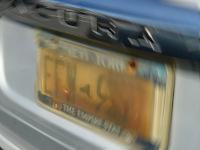

Ok ! That looks like the right image/post!

Now use it to find information about its owner.


In [17]:
# TODO: put the encoded image text in the following variable
encoded_image = social_df.loc[397, "image"]
MysteryUtils.check("image", encoded_image)


### Follow the Evidence

Now we can use the image we just found and the `dmv` dataset to narrow down the list of potential suspects from the gym.

In order to make the connection between `dmv` and `gym` datasets we need people's names. The `license_id` field can be _transformed_/_translated_ into a name using the `person` dataset one more time. The `apply()` function can help here with this step.

We can create a list of values by _applying_ a function to each row of a `DataFrame`.

For example, this combines the first and last name columns of a `DataFrame` into a list of names, and adds the result as a column to the original `DataFrame`:

```py
def combine_names(row):
  return row["first_name"] + " " + row["last_name"]

full_names = list(people_df.apply(combine_names, axis=1))

people_df["full_name"] = full_names
```

The overall process is:
- find people in the `dmv` dataset related to the image found in the previous step
- get their `name` from their `license_id`
- see if any of them are also in the list of suspects from the gym.

We have a couple of options to do the last step. We can use a `for` loop and iterate over the `gym` names while checking if any of them are in the list of names from the `dmv`. Or, we can do the opposite and iterate over the `dmv` names while checking if any of them are in the `gym` list.

OR, we can use `set` objects to find the _intersection_ between the $2$ lists. These `set` objects are like lists, but they only keep unique items.

```py
mylist = [0,2,2,4,4,4,6,7,8]
myset = set(mylist)
print(myset)
>>> {0, 2, 4, 6, 7, 8}
```

SO, they are great for doing _Venn diagram_ type of operations:

<div style="overflow:hidden;">
  <img style="margin-top:-40px;" src="https://media.geeksforgeeks.org/wp-content/uploads/20240711100807/Set-operations.png" width=600>
</div>

`set` [documentation](https://docs.python.org/3.10/library/stdtypes.html#set) and [examples](https://www.w3schools.com/python/python_sets.asp).

In [19]:
# TODO: get names from dmv dataset
efw_df = dmv_df[dmv_df["plate_number"].str.startswith("EFW")]
display(efw_df)

# TODO: cross-reference with names of potential suspects from gym
dmv_names = person_df[person_df["license_id"].isin(efw_df["license_id"])]["name"]

suspects = set(dmv_names) & set(potential_suspects_gym)
print(suspects)

,license_id,age,height,eye_color,hair_color,gender,plate_number,car_make,car_model
0,100280,72,57,brown,red,male,EFW9376,Acura,MDX
7,101586,57,70,amber,brown,male,EFW9377,Jaguar,XK
15,101859,31,71,blue,blonde,female,EFW9776,Nissan,Pathfinder
23,102648,63,70,black,blue,female,EFW9976,Buick,LaCrosse
30,103194,85,65,blue,grey,female,EFW9316,Dodge,Ram Van 2500
...,...,...,...,...,...,...,...,...,...
9791,980288,58,73,black,black,male,EFW8261,Acura,MDX
9814,982806,53,77,blue,brown,female,EFW9299,Acura,RDX
9896,989859,85,56,green,grey,female,EFW9071,BMW,M5
9978,997724,65,73,blue,blonde,male,EFW9010,Toyota,Highlander


{'Illiago Huaga'}


### Check Answer

Check the name of the suspect here.

In [20]:
# TODO: put the name of the suspect here
suspect_name = "Illiago Huaga"
MysteryUtils.check("suspect", suspect_name)

Ok ! That is the final suspect!
Mystery Solved !

